In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
data_552 = np.load(r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\BWR_3_2_552.txt_BWR_arrays.npz")
z_coordinate_552 = data_552["z_temperature"]
fuel_average_552 = data_552["fuel_average"]
fuel_centreline_552 = data_552["fuel_centreline"]
clad_inner_surface_552 = data_552["clad_inner_surface"]
clad_outer_surface_552 = data_552["clad_outer_surface"]
coolant_temperature_552 = data_552["coolant_temperature"]
linear_power_552 = data_552["linear_power"]
void_fraction_552 = data_552["void_fraction"]
z_void_fraction_552 = data_552["z_void_fraction"]

In [3]:
data_545 = np.load(r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\BWR_3_2_545.txt_BWR_arrays.npz")
z_temperature_545 = data_545["z_temperature"]
z_void_fraction_545 = data_545["z_void_fraction"]
fuel_average_545 = data_545["fuel_average"]
fuel_centreline_545 = data_545["fuel_centreline"]
clad_inner_surface_545 = data_545["clad_inner_surface"]
clad_outer_surface_545 = data_545["clad_outer_surface"]
coolant_temperature_545 = data_545["coolant_temperature"]
void_fraction_545 = data_545["void_fraction"]
linear_power_545 = data_545["linear_power"]

In [4]:
data_530 = np.load(r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\BWR_3_2_530.txt_BWR_arrays.npz")
z_temperature_530 = data_530["z_temperature"]
z_void_fraction_530 = data_530["z_void_fraction"]
fuel_average_530 = data_530["fuel_average"]
fuel_centreline_530 = data_530["fuel_centreline"]
clad_inner_surface_530 = data_530["clad_inner_surface"]
clad_outer_surface_530 = data_530["clad_outer_surface"]
coolant_temperature_530 = data_530["coolant_temperature"]
void_fraction_530 = data_530["void_fraction"]
linear_power_530 = data_530["linear_power"]

# Plotting

In [24]:
color_list = ["#D55E00", "#0072B2", "#009E73"]
marker_list = ["o", "D", "s"]

labels = [
    "552 K",
    "545 K",
    "530 K"
]

from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple

legend_elements = []

for color, marker, label in zip(color_list, marker_list, labels):
    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='none',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements.append(((line, marker_handle), label))

void_fraction_datasets = [void_fraction_552, void_fraction_545, void_fraction_530]

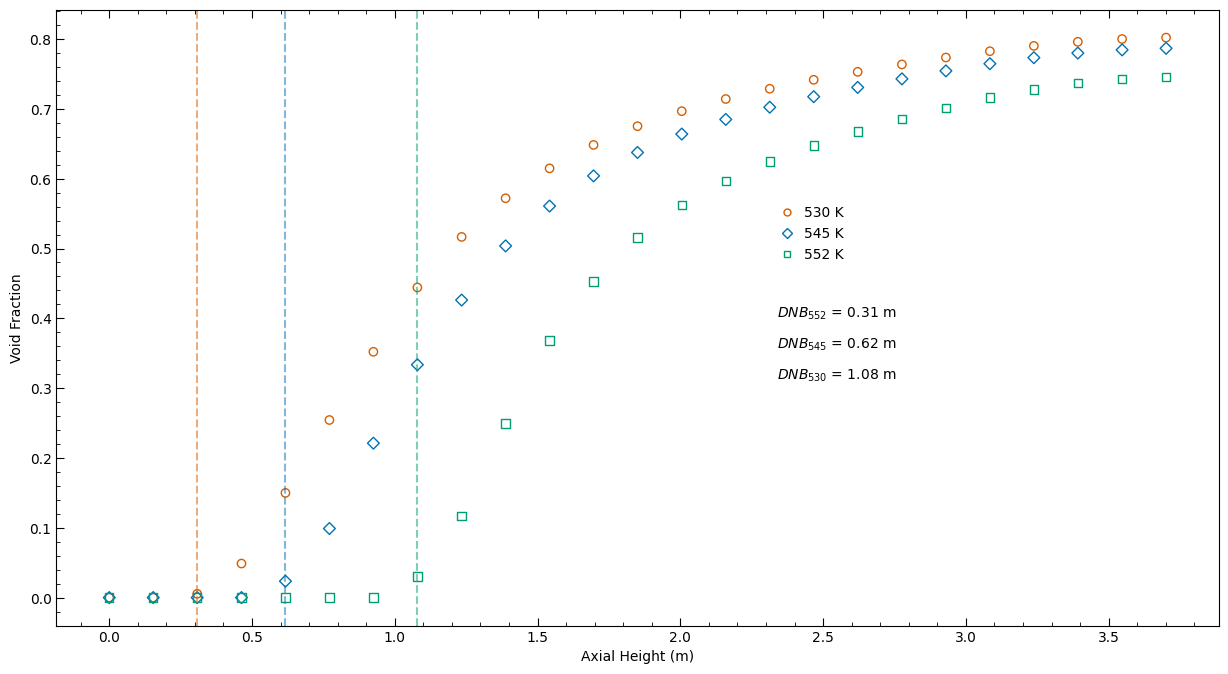

In [26]:
#######
# Setup
#######

fig = plt.figure(figsize=(15, 8))

gs = fig.add_gridspec(
    1, 1
)

ax_main = fig.add_subplot(gs[0])

###########
# Main Plot
###########

for ydata, colour, marker in zip(
        void_fraction_datasets, color_list, marker_list):
    ax_main.scatter(z_void_fraction_552, ydata,
                    marker=marker, color=colour, facecolor="none")

for xdata, ydata, color, ycoord,label in zip([z_void_fraction_552, z_void_fraction_545, z_void_fraction_530],
                               void_fraction_datasets,
                                color_list,
                                [0.5, 0.45, 0.4],
                                [552, 545, 530]):

    first_nonzero_index = next((i for i, x in enumerate(ydata) if x != 0), None)
    ax_main.axvline(xdata[first_nonzero_index],
                    color=color, alpha=0.5, linestyle="--")

    ax_main.text(
    0.62, ycoord,
    rf"$DNB_{{{label}}}$ = {xdata[first_nonzero_index]:.2f} m",
    transform=ax_main.transAxes,
    color="black",
    fontsize=10
    )

ax_main.legend(
    handles=[item[0] for item in legend_elements],
    labels=[item[1] for item in legend_elements],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.6, 0.7),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

#####################
# Formatting and Save
#####################

ax_main.set_xlabel("Axial Height (m)")
ax_main.set_ylabel("Void Fraction")

for ax in [ax_main]:
    ax.minorticks_on()

    ax.tick_params(
        which='major',
        size=6,
        direction='in',
        top=True
    )

    ax.tick_params(
        which='minor',
        size=3,
        direction='in',
        top=True
    )
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\BWR_3_2_Void_Fraction_Plot.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()